# 03 — Trực quan hóa dữ liệu
**Người thực hiện: Trọng**


In [ ]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import BaseEstimator, TransformerMixin
from IPython.display import display

candidates = [Path('dataset/csv'), Path('../dataset/csv'),
              Path('data/aog-2026-spring-mvp/csv'), Path('../data/aog-2026-spring-mvp/csv')]
DATA_PATH = next((p for p in candidates if all((p / f).exists() for f in
                    ['train.csv', 'validation.csv', 'test.csv', 'heroes.csv'])), None)
if DATA_PATH is None:
    raise FileNotFoundError('Đặt bốn CSV tại dataset/csv hoặc sửa candidates cho đúng đường dẫn.')
OUT = Path('visualization_output')
OUT.mkdir(exist_ok=True)
raw = {s: pd.read_csv(DATA_PATH / f'{s}.csv', dtype=str)
       for s in ['train', 'validation', 'test']}
heroes_df = pd.read_csv(DATA_PATH / 'heroes.csv', dtype=str)
hero_names = heroes_df.set_index('hero_id')['name'].to_dict()
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 10,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'figure.dpi': 110, 'axes.titleweight': 'bold'})
COLORS = ['#2563eb', '#14b8a6', '#f59e0b']
def save(name):
    plt.tight_layout()
    plt.savefig(OUT / f'{name}.png', dpi=170, bbox_inches='tight')
    plt.show()
print('Dữ liệu:', DATA_PATH.resolve())


Dữ liệu: D:\Python của trọng\Khai Pha\liqi_recommender\data\aog-2026-spring-mvp\csv


## 1. Tái tạo kết quả cleaning và kiểm tra chất lượng
Giữ nguyên quy tắc cleaning của notebook nguồn. Fallback `unknown` không được tính như một tướng thực trong các biểu đồ.

In [ ]:
def clean_dataset(df, is_train=True):
    df = df.copy()

    # 1. Làm sạch nhãn team_a_win (nếu có)
    if 'team_a_win' in df.columns:
        df['team_a_win'] = df['team_a_win'].astype(str).str.lower().map({'true': 1, 'false': 0})
        if is_train:
            # Loại bỏ dòng thiếu nhãn ở tập Train (nếu có)
            df = df.dropna(subset=['team_a_win'])
            df['team_a_win'] = df['team_a_win'].astype(int)

    # 2. Chuẩn hóa chuỗi (strip khoảng trắng)
    for col in ['team_a_side', 'patch_id']:
        if col in df.columns:
            df[col] = df[col].astype(str).str.strip()

    # 3. Parse JSON đội hình
    def parse_heroes(val):
        try:
            ids = json.loads(val)
            if isinstance(ids, list) and len(ids) == 5:
                return ids
        except:
            pass
        return ["unknown"] * 5  # Điền fallback nếu lỗi JSON/sai số lượng

    df['team_a_heroes_parsed'] = df['team_a_heroes'].apply(parse_heroes)
    df['team_b_heroes_parsed'] = df['team_b_heroes'].apply(parse_heroes)

    return df


class HeroBagEncoder(BaseEstimator, TransformerMixin):
    def __init__(self):
        self.vocab_ = []
        self.hero_to_idx_ = {}

    def fit(self, X, y=None):
        # Build từ điển tướng từ tập Train
        unique_heroes = set()
        for _, row in X.iterrows():
            unique_heroes.update(row['team_a_heroes_parsed'])
            unique_heroes.update(row['team_b_heroes_parsed'])

        # Loại bỏ ID không hợp lệ nếu có
        self.vocab_ = sorted(list(unique_heroes))
        self.hero_to_idx_ = {h: i for i, h in enumerate(self.vocab_)}
        return self

    def transform(self, X):
        n_samples = len(X)
        n_features = len(self.vocab_)
        matrix = np.zeros((n_samples, n_features), dtype=np.int8)

        for i, (_, row) in enumerate(X.iterrows()):
            # Team A +1
            for h in row['team_a_heroes_parsed']:
                if h in self.hero_to_idx_:
                    matrix[i, self.hero_to_idx_[h]] += 1
            # Team B -1
            for h in row['team_b_heroes_parsed']:
                if h in self.hero_to_idx_:
                    matrix[i, self.hero_to_idx_[h]] -= 1

        feature_names = [f"hero_{h}" for h in self.vocab_]
        return pd.DataFrame(matrix, columns=feature_names, index=X.index)


clean = {s: clean_dataset(df, is_train=(s == 'train')) for s, df in raw.items()}
train_clean = clean['train']
hero_encoder = HeroBagEncoder()
X_train_heroes = hero_encoder.fit_transform(train_clean)
quality = []
for s, df in clean.items():
    parsed = df['team_a_heroes_parsed'].tolist() + df['team_b_heroes_parsed'].tolist()
    quality.append({'Tập': s, 'Trước cleaning': len(raw[s]), 'Sau cleaning': len(df),
                    'Thiếu nhãn': int(df['team_a_win'].isna().sum()),
                    'Đội hình fallback': sum('unknown' in x for x in parsed),
                    'ID ngoài danh mục': sum(h not in hero_names and h != 'unknown' for x in parsed for h in x),
                    'Đội hình trùng tướng': sum(len(set(x)) != len(x) for x in parsed),
                    'Trùng game_id': int(df['game_id'].duplicated().sum()) if 'game_id' in df else None})
quality = pd.DataFrame(quality).set_index('Tập')
display(quality)
quality.to_csv(OUT / 'quality.csv', encoding='utf-8-sig')
print('Lưu ý: cleaning nguồn chưa loại ID ngoài danh mục hay dòng trùng; bảng trên chỉ kiểm tra và báo cáo.')


,Trước cleaning,Sau cleaning,Thiếu nhãn,Đội hình fallback,ID ngoài danh mục,Đội hình trùng tướng,Trùng game_id
Tập,,,,,,,
train,231,231,0,0,0,0,0
validation,28,28,0,0,0,0,0
test,40,40,0,0,0,0,0


Lưu ý: cleaning nguồn chưa loại ID ngoài danh mục hay dòng trùng; bảng trên chỉ kiểm tra và báo cáo.


## 2. Quy mô và phân bố nhãn
Nhãn 0 = Team A thua, 1 = Team A thắng. Luôn reindex theo [0, 1] để không đảo tên nhãn khi value_counts sắp xếp theo tần suất.

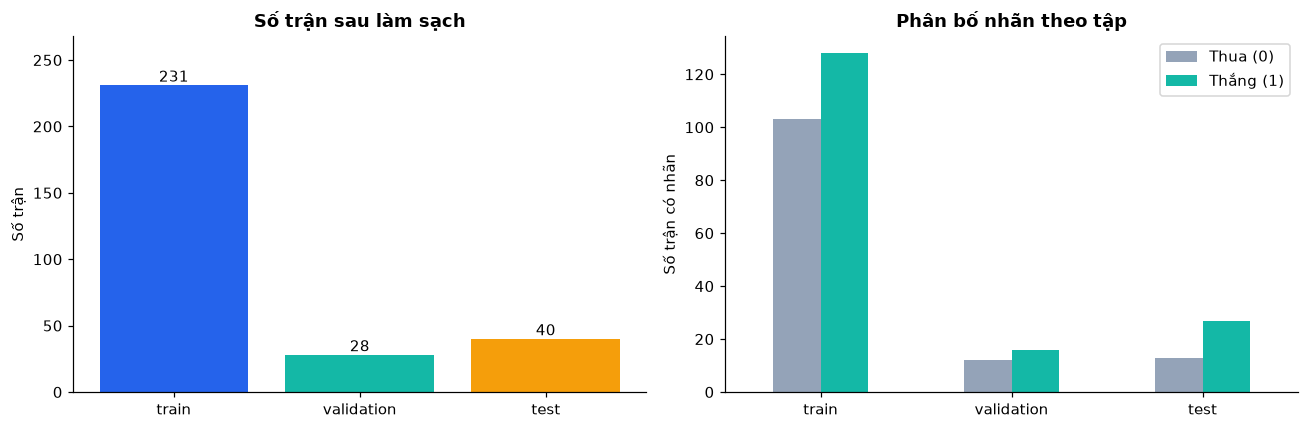

,Thua (0),Thắng (1)
train,103,128
validation,12,16
test,13,27


Nhận xét: Train có 231 trận, Team A thắng 55.4%. Lớp chiếm đa số có tỷ trọng 55.4%; đây là mốc tham khảo cho dự đoán lớp đa số.


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sizes = pd.Series({s: len(d) for s, d in clean.items()})
bars = axes[0].bar(sizes.index, sizes.values, color=COLORS)
axes[0].bar_label(bars)
axes[0].set(title='Số trận sau làm sạch', ylabel='Số trận', ylim=(0, sizes.max()*1.16))
labels = pd.DataFrame({s: d['team_a_win'].value_counts().reindex([0, 1], fill_value=0) for s, d in clean.items()}).T
labels.columns = ['Thua (0)', 'Thắng (1)']
labels.plot.bar(ax=axes[1], color=['#94a3b8', '#14b8a6'], rot=0)
axes[1].set(title='Phân bố nhãn theo tập', ylabel='Số trận có nhãn')
save('01_quy_mo_va_nhan')
display(labels)
rate = train_clean['team_a_win'].mean()
print(f'Nhận xét: Train có {len(train_clean)} trận, Team A thắng {rate:.1%}. '
      f'Lớp chiếm đa số có tỷ trọng {max(rate, 1-rate):.1%}; đây là mốc tham khảo cho dự đoán lớp đa số.')


## 3. Phía bản đồ và phiên bản
Tỷ lệ thắng dưới đây là của Team A theo phía Team A. Patch là nhóm phân loại; không diễn giải thành chuỗi thời gian.

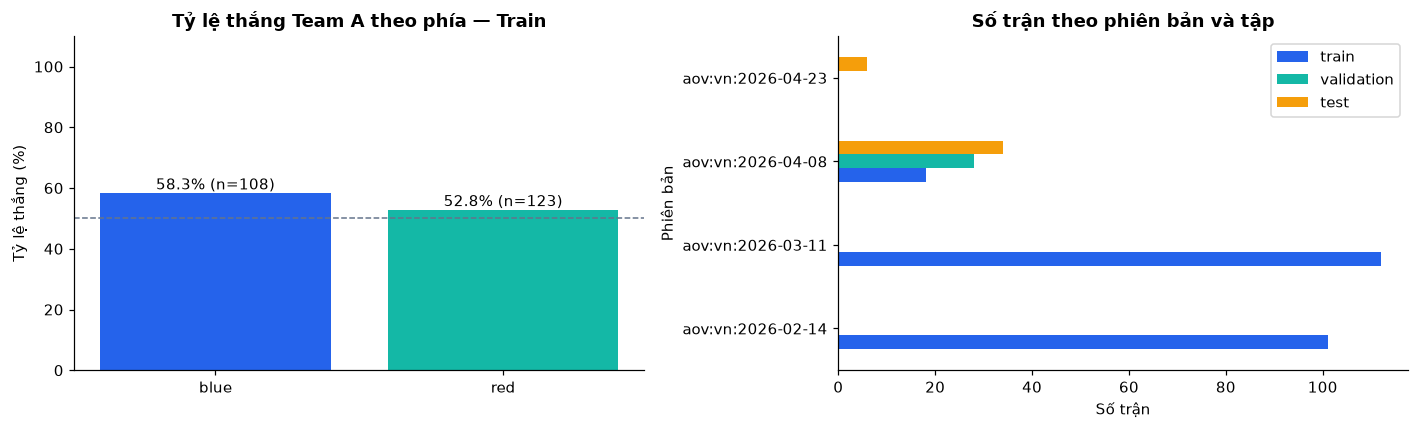

,Số trận,Có nhãn,Tỷ lệ thắng
team_a_side,,,
blue,108,108,0.583333
red,123,123,0.528455


Phiên bản chưa xuất hiện trong Train: {'validation': [], 'test': ['aov:vn:2026-04-23']}
Nhận xét: chênh lệch tỷ lệ thắng có thể liên quan đội thi đấu và quy mô mẫu; chưa đủ để kết luận phía nào gây lợi thế.


In [ ]:
side = train_clean.groupby('team_a_side')['team_a_win'].agg(['size', 'count', 'mean'])
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
bars = axes[0].bar(side.index, side['mean']*100, color=COLORS[:len(side)])
axes[0].bar_label(bars, labels=[f'{v:.1%} (n={n})' for v, n in zip(side['mean'], side['count'])])
axes[0].axhline(50, color='#64748b', ls='--', lw=1)
axes[0].set(title='Tỷ lệ thắng Team A theo phía — Train', ylabel='Tỷ lệ thắng (%)', ylim=(0, 110))
patch = pd.DataFrame({s: d['patch_id'].value_counts() for s, d in clean.items()}).fillna(0).astype(int)
patch.plot.barh(ax=axes[1], color=COLORS)
axes[1].set(title='Số trận theo phiên bản và tập', xlabel='Số trận', ylabel='Phiên bản')
save('02_side_va_patch')
display(side.rename(columns={'size':'Số trận', 'count':'Có nhãn', 'mean':'Tỷ lệ thắng'}))
unseen = {s: sorted(set(clean[s]['patch_id']) - set(train_clean['patch_id'])) for s in ['validation','test']}
print('Phiên bản chưa xuất hiện trong Train:', unseen)
print('Nhận xét: chênh lệch tỷ lệ thắng có thể liên quan đội thi đấu và quy mô mẫu; chưa đủ để kết luận phía nào gây lợi thế.')


## 4. Tướng được chọn nhiều nhất — Train
Đếm lượt xuất hiện từ đội hình đã parse của cả hai đội; tỷ lệ chọn = số trận có tướng / tổng trận Train.

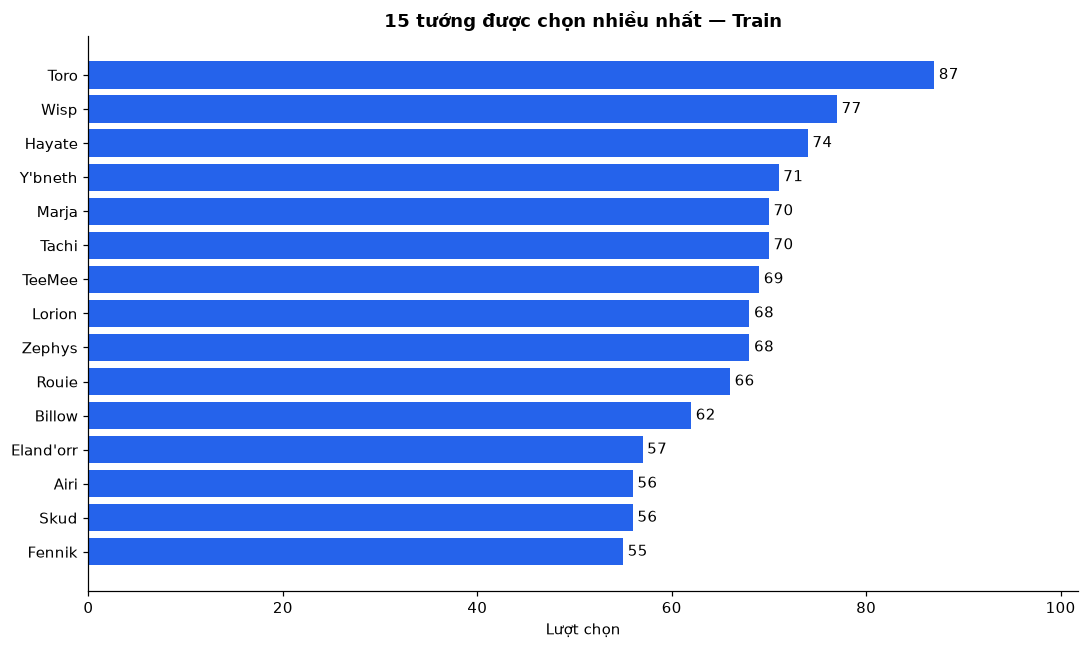

Nhận xét: Toro xuất hiện nhiều nhất với 87 lượt, trong 37.7% số trận Train.


In [ ]:
records = []
for i, (_, row) in enumerate(train_clean.iterrows()):
    for team in ['a', 'b']:
        win = row['team_a_win'] if team == 'a' else 1 - row['team_a_win']
        for h in set(row[f'team_{team}_heroes_parsed']):
            if h != 'unknown' and h in hero_names:
                records.append({'match': i, 'team': team, 'hero_id': h, 'win': win})
appearances = pd.DataFrame(records)
stats = appearances.groupby('hero_id').agg(picks=('win','size'), labeled=('win','count'), wins=('win','sum'), games=('match','nunique'))
stats['name'] = stats.index.map(hero_names)
stats['pick_rate'] = stats['games'] / len(train_clean)
stats['win_rate'] = stats['wins'] / stats['labeled']
stats = stats.sort_values(['picks', 'name'], ascending=[False, True])
top = stats.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(top['name'], top['picks'], color='#2563eb')
ax.bar_label(bars, padding=3)
ax.set(title='15 tướng được chọn nhiều nhất — Train', xlabel='Lượt chọn', xlim=(0, top['picks'].max()*1.17))
save('03_top_tuong')
stats.to_csv(OUT / 'hero_statistics_train.csv', encoding='utf-8-sig')
best = stats.iloc[0]
print(f"Nhận xét: {best['name']} xuất hiện nhiều nhất với {int(best['picks'])} lượt, trong {best['pick_rate']:.1%} số trận Train.")


## 5. Tỷ lệ thắng và mức phổ biến — Train
Chỉ xếp hạng tướng có ít nhất 10 lượt có nhãn. Thanh ngang là khoảng Wilson 95%, mô tả độ bất định theo mô hình nhị thức

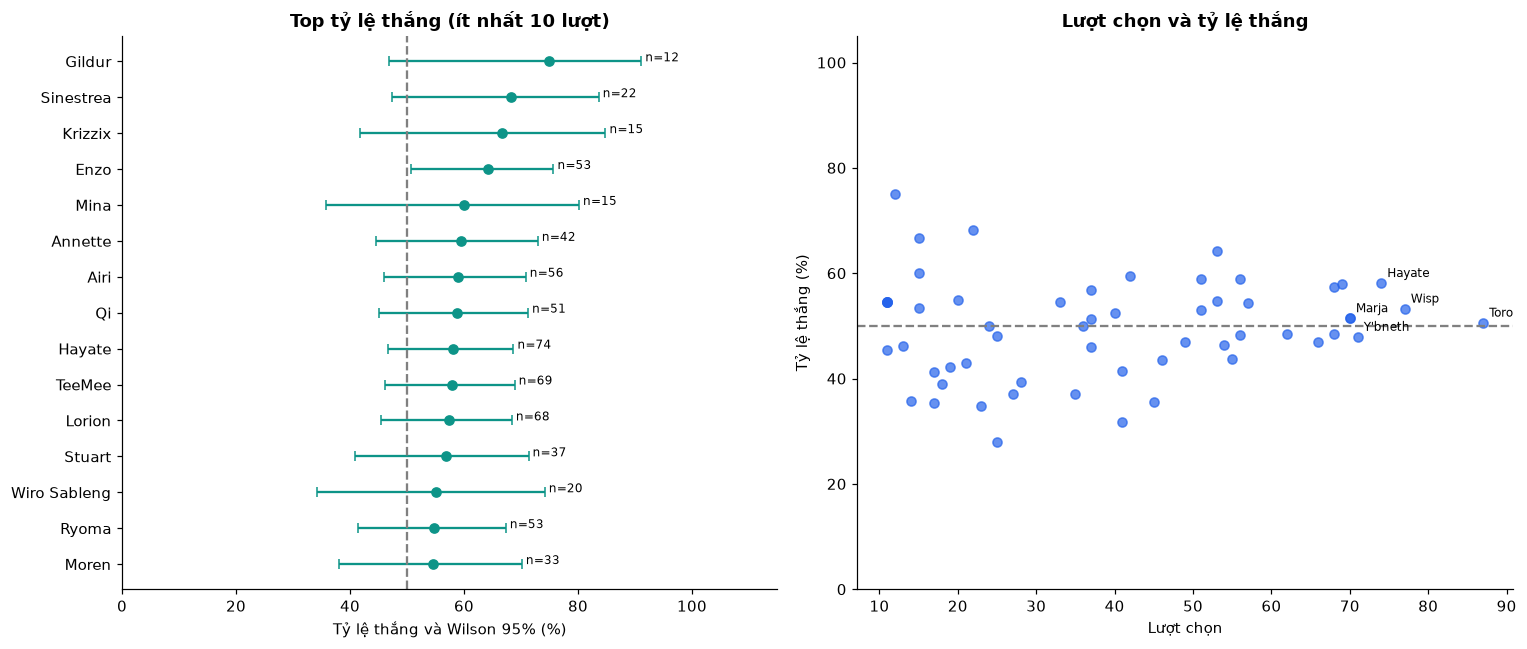

Nhận xét: 57/83 tướng đạt ngưỡng 10 lượt có nhãn. Tướng phổ biến không nhất thiết có tỷ lệ thắng cao; mẫu nhỏ làm khoảng bất định rộng.


In [ ]:
MIN_PICKS = 10
eligible = stats[stats['labeled'] >= MIN_PICKS].copy()
n, p, z = eligible['labeled'], eligible['win_rate'], 1.96
center = (p + z*z/(2*n)) / (1+z*z/n)
half = z*np.sqrt(p*(1-p)/n + z*z/(4*n*n)) / (1+z*z/n)
eligible['lower'], eligible['upper'] = center-half, center+half
rank = eligible.sort_values(['win_rate','picks'], ascending=False).head(15).iloc[::-1]
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
if not rank.empty:
    axes[0].errorbar(rank['win_rate']*100, rank['name'],
        xerr=np.vstack([(rank['win_rate']-rank['lower'])*100, (rank['upper']-rank['win_rate'])*100]),
        fmt='o', color='#0d9488', capsize=3)
    for _, r in rank.iterrows():
        axes[0].annotate(f" n={int(r['labeled'])}", (r['upper']*100, r['name']), fontsize=8)
axes[0].axvline(50, color='gray', ls='--')
axes[0].set(title=f'Top tỷ lệ thắng (ít nhất {MIN_PICKS} lượt)', xlabel='Tỷ lệ thắng và Wilson 95% (%)', xlim=(0, 115))
axes[1].scatter(eligible['picks'], eligible['win_rate']*100, color='#2563eb', alpha=.7)
for _, r in eligible.head(5).iterrows():
    axes[1].annotate(r['name'], (r['picks'], r['win_rate']*100), xytext=(4,4), textcoords='offset points', fontsize=8)
axes[1].axhline(50, color='gray', ls='--')
axes[1].set(title='Lượt chọn và tỷ lệ thắng', xlabel='Lượt chọn', ylabel='Tỷ lệ thắng (%)', ylim=(0,105))
save('04_ty_le_thang')
print(f'Nhận xét: {len(eligible)}/{len(stats)} tướng đạt ngưỡng {MIN_PICKS} lượt có nhãn. Tướng phổ biến không nhất thiết có tỷ lệ thắng cao; mẫu nhỏ làm khoảng bất định rộng.')


## 6. Các cặp tướng cùng đội — Train
Heatmap đếm số đội hình có cả hai tướng trong 12 tướng phổ biến nhất. Đặt đường chéo bằng 0; mỗi cặp đối xứng biểu diễn cùng một số đếm.

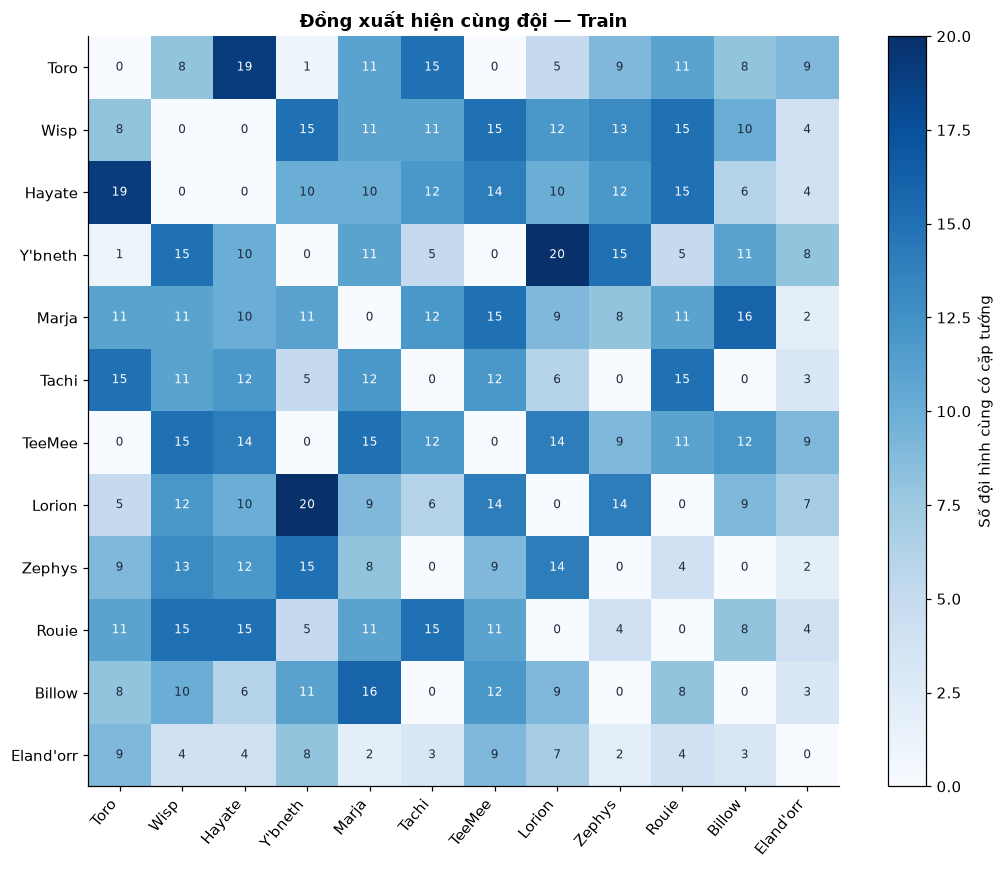

Nhận xét: các ô đậm giúp xác định cặp thường đi cùng nhau để khảo sát hệ gợi ý; cần đánh giá riêng để xác nhận hiệu quả gợi ý.


In [ ]:
from itertools import combinations
ids = stats.head(12).index.tolist()
co = pd.DataFrame(0, index=ids, columns=ids)
for _, row in train_clean.iterrows():
    for team in ['a','b']:
        hs = sorted(set(row[f'team_{team}_heroes_parsed']) & set(ids))
        for a, b in combinations(hs, 2):
            co.loc[a,b] += 1
            co.loc[b,a] += 1
fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(co.values, cmap='Blues')
names = [hero_names[h] for h in ids]
ax.set_xticks(range(len(ids)), names, rotation=50, ha='right')
ax.set_yticks(range(len(ids)), names)
for i in range(len(ids)):
    for j in range(len(ids)):
        ax.text(j, i, str(co.iloc[i,j]), ha='center', va='center', fontsize=8,
                color='white' if co.iloc[i,j] > co.values.max()/2 else '#1e293b')
fig.colorbar(im, ax=ax, label='Số đội hình cùng có cặp tướng')
ax.set_title('Đồng xuất hiện cùng đội — Train')
save('05_cap_tuong')
print('Nhận xét: các ô đậm giúp xác định cặp thường đi cùng nhau để khảo sát hệ gợi ý; cần đánh giá riêng để xác nhận hiệu quả gợi ý.')


## 7. Kiểm tra ma trận đặc trưng sau mã hóa
Giữ đúng mã hóa nguồn: tướng Team A +1, Team B −1. Fit encoder và OneHotEncoder chỉ trên Train; các cột không đổi ít giúp phân biệt trận trong Train.

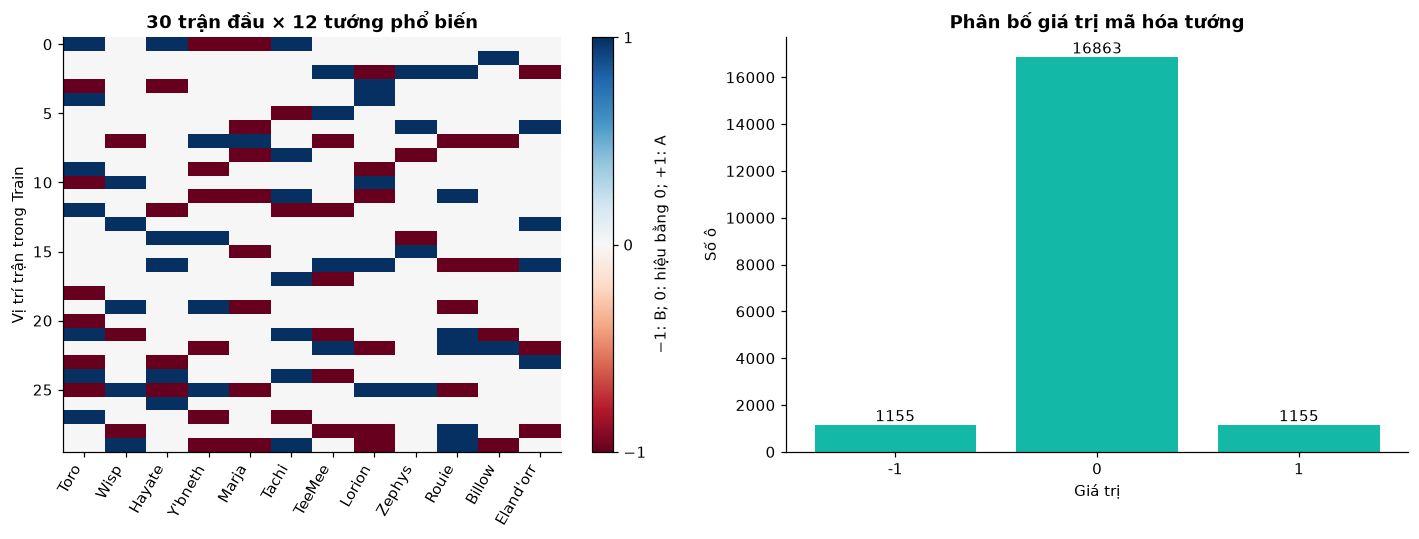

Kích thước X_train: (231, 88); tướng: 83; phân loại: 5.
Tỷ lệ ô 0 trong khối tướng: 88.0%.
Các cột không đổi: []
Nhận xét: khối tướng nhiều ô 0 vì mỗi trận chỉ có 10 lượt chọn. Giá trị 0 cũng có thể do cùng tướng ở hai đội triệt tiêu; không luôn đồng nghĩa không xuất hiện.


In [ ]:
from sklearn.preprocessing import OneHotEncoder
ohe = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
cat = ['team_a_side','patch_id']
Xcat = pd.DataFrame(ohe.fit_transform(train_clean[cat]), columns=ohe.get_feature_names_out(cat), index=train_clean.index)
X_train = pd.concat([X_train_heroes, Xcat], axis=1)
constant = X_train.columns[X_train.nunique() <= 1].tolist()
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
hero_cols = ['hero_' + h for h in ids]
im = axes[0].imshow(X_train_heroes[hero_cols].head(30), aspect='auto', cmap='RdBu', vmin=-1, vmax=1)
axes[0].set_xticks(range(len(ids)), names, rotation=60, ha='right')
axes[0].set(title='30 trận đầu × 12 tướng phổ biến', ylabel='Vị trí trận trong Train')
fig.colorbar(im, ax=axes[0], ticks=[-1,0,1], label='−1: B; 0: hiệu bằng 0; +1: A')
values = pd.Series(X_train_heroes.to_numpy().ravel()).value_counts().sort_index()
bars = axes[1].bar(values.index.astype(str), values.values, color='#14b8a6')
axes[1].bar_label(bars)
axes[1].set(title='Phân bố giá trị mã hóa tướng', xlabel='Giá trị', ylabel='Số ô')
save('06_ma_tran_dac_trung')
print(f'Kích thước X_train: {X_train.shape}; tướng: {X_train_heroes.shape[1]}; phân loại: {Xcat.shape[1]}.')
print(f'Tỷ lệ ô 0 trong khối tướng: {(X_train_heroes.to_numpy()==0).mean():.1%}.')
print('Các cột không đổi:', constant)
print('Nhận xét: khối tướng nhiều ô 0 vì mỗi trận chỉ có 10 lượt chọn. Giá trị 0 cũng có thể do cùng tướng ở hai đội triệt tiêu; không luôn đồng nghĩa không xuất hiện.')
